# Checkpoint 02 — Regressão linear com PIB e Índice ABCR

**Integrantes**

| Nome | RM |
|---|---|
| Felipe Macedo | RM 570990 |

**Pergunta:** existe relação entre a atividade econômica brasileira (PIB) e o fluxo de veículos nas rodovias pedagiadas (Índice ABCR)? Dá para estimar o fluxo a partir do PIB com uma regressão linear simples?

## 1. Fontes consultadas

| Indicador | Fonte | Série usada |
|---|---|---|
| PIB | IBGE — [SIDRA, Tabela 1620](https://sidra.ibge.gov.br/tabela/1620) | Série encadeada do índice de volume trimestral (base: média de 1995 = 100), Brasil, "PIB a preços de mercado", **sem ajuste sazonal** |
| Fluxo de veículos | ABCR — [Índice ABCR](https://melhoresrodovias.org.br/indice-abcr_2/), botão "Ver histórico" | Série **original** (sem ajuste sazonal), Brasil, fluxo **total** (leves + pesados), número-índice mensal |

Período: 2006 a 2025 (20 anos completos em comum).

O PIB foi obtido pela API do SIDRA (consulta em 07/10/2026) e salvo em `dados/pib_trimestral_sidra1620.csv`:

`https://apisidra.ibge.gov.br/values/t/1620/n1/all/v/583/p/200601-202504/c11255/90707`

(`t/1620` = tabela, `v/583` = índice de volume encadeado, `c11255/90707` = PIB a preços de mercado.)

A planilha da ABCR (`abcr_0826.xlsx`) fica em `dados/` exatamente como foi baixada do site.

In [1]:
import datetime
import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ANO_INICIAL, ANO_FINAL = 2006, 2025

## 2. Organização da base

### 2.1 PIB: de trimestral para anual

O SIDRA entrega um número-índice por trimestre. Para ter um valor por ano, tiramos a **média dos quatro trimestres**. Antes, conferimos se todo ano tem mesmo 4 trimestres — uma média com trimestre faltando ficaria enviesada pela sazonalidade.

In [2]:
pib_tri = pd.read_csv("dados/pib_trimestral_sidra1620.csv")

# Conferência: 20 anos x 4 trimestres, sem buracos
contagem = pib_tri.groupby("Ano")["Trimestre"].nunique()
assert (contagem == 4).all() and len(contagem) == 20, "Há ano com trimestre faltando no PIB"

pib_anual = (pib_tri.groupby("Ano")["PIB_indice_trimestral"].mean()
             .rename("PIB_indice").reset_index())
pib_tri.head(8)

,Ano,Trimestre,PIB_indice_trimestral
0,2006,1,128.18
1,2006,2,132.13
2,2006,3,136.72
3,2006,4,136.37
4,2007,1,134.84
5,2007,2,140.77
6,2007,3,144.75
7,2007,4,145.43


### 2.2 ABCR: de mensal para anual

A planilha da ABCR traz várias séries (leves, pesados, total; Brasil e estados; original e dessazonalizada). Precisamos de **uma só**: original, Brasil, total.

A função abaixo abre a planilha sem assumir posição fixa de cabeçalho: ela acha a coluna de datas, lê o texto do cabeçalho acima dela e escolhe a coluna "total" do Brasil. Ela **imprime o que escolheu** para dar para conferir contra a planilha. Se a escolha automática estiver errada, basta informar `aba=` e `coluna=` manualmente.

In [3]:
def carregar_abcr(caminho, aba=None, coluna=None):
    """Devolve a série mensal (Data, ABCR_indice) da planilha histórica da ABCR."""
    abas = pd.read_excel(caminho, sheet_name=None, header=None)
    print("Abas na planilha:", list(abas))

    # 1) Aba: a da série original (sem ajuste sazonal)
    if aba is None:
        candidatas = [n for n in abas if "orig" in n.lower()]
        aba = candidatas[0] if candidatas else list(abas)[0]
    bruto = abas[aba]

    # 2) Coluna de datas: a que tem mais células do tipo data
    #    (pd.NaT também é "datetime" para o Python, por isso o notna: senão o cabeçalho vazio contaria como data)
    eh_data = bruto.apply(lambda c: c.map(lambda v: isinstance(v, datetime.datetime) and pd.notna(v)))
    if eh_data.sum().max() < 12:
        raise ValueError(f"Não achei coluna de datas na aba '{aba}'. Informe aba= e coluna=.")
    col_data = eh_data.sum().idxmax()
    primeira_linha = eh_data[col_data].idxmax()

    # 3) Cabeçalho: tudo que está acima da primeira data.
    #    ffill(axis=1) repete o texto de células mescladas ("BRASIL" cobrindo 3 colunas).
    cab = bruto.loc[:primeira_linha - 1].ffill(axis=1)
    rotulos = cab.apply(lambda c: " | ".join(str(v) for v in c.dropna()).lower())

    if coluna is None:
        totais = [c for c in bruto.columns if "total" in rotulos[c] and c != col_data]
        brasil = [c for c in totais if "brasil" in rotulos[c]]
        if not totais:
            raise ValueError(f"Não achei coluna 'total' na aba '{aba}'. Cabeçalhos: {rotulos.to_dict()}")
        coluna = (brasil or totais)[0]
    print(f"Aba usada: '{aba}' | coluna usada: {coluna} -> '{rotulos[coluna]}'")

    serie = pd.DataFrame({
        "Data": pd.to_datetime(bruto.loc[primeira_linha:, col_data], errors="coerce"),
        "ABCR_indice_mensal": pd.to_numeric(bruto.loc[primeira_linha:, coluna], errors="coerce"),
    }).dropna()
    return serie.reset_index(drop=True)


arquivos = sorted(glob.glob("dados/abcr*.xls*"))
if not arquivos:
    raise FileNotFoundError("Coloque a planilha histórica da ABCR (abcr_0826.xlsx) na pasta dados/")
arquivo_abcr = arquivos[-1]
abcr_mes = carregar_abcr(arquivo_abcr)          # se precisar: carregar_abcr(arquivo_abcr, aba="...", coluna=3)
abcr_mes["Ano"] = abcr_mes["Data"].dt.year
abcr_mes["Mes"] = abcr_mes["Data"].dt.month
abcr_mes = abcr_mes[abcr_mes["Ano"].between(ANO_INICIAL, ANO_FINAL)]

# Conferências: 12 meses em todos os 20 anos, e valores com cara de número-índice (não de variação %)
meses = abcr_mes.groupby("Ano")["Mes"].nunique()
assert (meses == 12).all() and len(meses) == 20, f"Meses faltando na ABCR:\n{meses[meses != 12]}"
assert abcr_mes["ABCR_indice_mensal"].min() > 30, "Valores baixos demais: parece variação %, não número-índice"

abcr_mes[["Ano", "Mes", "ABCR_indice_mensal"]].to_csv("dados/abcr_mensal_original_total_brasil.csv", index=False)
abcr_anual = (abcr_mes.groupby("Ano")["ABCR_indice_mensal"].mean()
              .rename("ABCR_indice").reset_index())
abcr_mes.head(12)

Abas na planilha: ['(A) Gráficos', '(B) Quadros', '(C) Original', '(D) Dessazonalizado']
Aba usada: '(C) Original' | coluna usada: 3 -> 'brasil | série original - número índice (1999=100) | total'


,Data,ABCR_indice_mensal,Ano,Mes
84,2006-01-01,117.484382,2006,1
85,2006-02-01,100.130970,2006,2
86,2006-03-01,105.832032,2006,3
87,2006-04-01,104.449614,2006,4
88,2006-05-01,102.699143,2006,5
89,2006-06-01,97.745498,2006,6
90,2006-07-01,109.587526,2006,7
91,2006-08-01,106.098928,2006,8
92,2006-09-01,105.387649,2006,9
93,2006-10-01,108.575872,2006,10


### 2.3 Tabela final

Juntamos as duas séries pelo `Ano`. O `merge` com `validate="one_to_one"` garante que cada ano aparece uma única vez em cada lado — é o que impede de parear, por engano, o PIB de um ano com o fluxo de outro.

In [4]:
base = pib_anual.merge(abcr_anual, on="Ano", how="inner", validate="one_to_one").sort_values("Ano")
base = base.round({"PIB_indice": 2, "ABCR_indice": 2}).reset_index(drop=True)
assert len(base) == 20 and base.notna().all().all()

base.to_csv("dados/base_anual_pib_abcr.csv", index=False)
base

,Ano,PIB_indice,ABCR_indice
0,2006,133.35,107.49
1,2007,141.45,113.99
2,2008,148.65,120.91
3,2009,148.47,123.60
4,2010,159.64,133.12
5,2011,165.98,141.44
6,2012,169.18,147.97
7,2013,174.26,153.59
8,2014,175.14,157.23
9,2015,168.93,154.25


## 3. Análise da relação

Dispersão com o PIB no eixo horizontal e o Índice ABCR no vertical. Cada ponto é um ano.

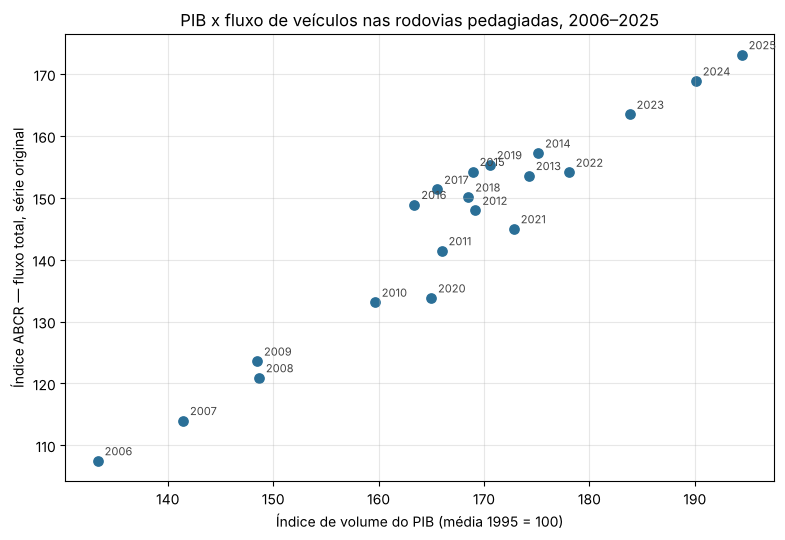

In [5]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(base["PIB_indice"], base["ABCR_indice"], s=45, color="#2a6f97")
for _, r in base.iterrows():
    ax.annotate(int(r["Ano"]), (r["PIB_indice"], r["ABCR_indice"]),
                textcoords="offset points", xytext=(5, 4), fontsize=8, color="#444")
ax.set_xlabel("Índice de volume do PIB (média 1995 = 100)")
ax.set_ylabel("Índice ABCR — fluxo total, série original")
ax.set_title("PIB x fluxo de veículos nas rodovias pedagiadas, 2006–2025")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
r_total = base["PIB_indice"].corr(base["ABCR_indice"])          # Pearson
r_treino = base.iloc[:16]["PIB_indice"].corr(base.iloc[:16]["ABCR_indice"])
print(f"Correlação de Pearson, 2006-2025 (20 anos): r = {r_total:.3f}")
print(f"Correlação de Pearson, 2006-2021 (treino):  r = {r_treino:.3f}")

Correlação de Pearson, 2006-2025 (20 anos): r = 0.964
Correlação de Pearson, 2006-2021 (treino):  r = 0.949


**Como ler:** o coeficiente de Pearson vai de −1 a +1 e mede o quanto os pontos se alinham em uma reta. Perto de +1, anos de PIB maior são também anos de fluxo maior.

**Cuidado na interpretação:** as duas séries crescem ao longo do tempo. Duas coisas que simplesmente sobem com os anos aparecem correlacionadas mesmo sem ligação direta entre elas, então parte desse `r` é tendência comum. Além disso, correlação não mostra causa: aqui faz sentido econômico que mais atividade gere mais transporte de carga e mais viagens, mas o número sozinho não prova a direção — e o próprio IBGE usa o Índice ABCR como insumo no cálculo do PIB, então as duas medidas não são totalmente independentes.

## 4. Treinamento do modelo

- **Entrada (`X`)**: `PIB_indice` &nbsp;|&nbsp; **Alvo (`y`)**: `ABCR_indice`
- **Treino**: os 16 primeiros anos (2006–2021) &nbsp;|&nbsp; **Teste**: os 4 últimos (2022–2025)

**Por que não usar `train_test_split`?** Por padrão ele embaralha as linhas. Em dado temporal isso deixa o modelo "ver o futuro": treinaria com 2024 para prever 2019. Cortando pela ordem cronológica, o teste simula o uso real — estimar anos que o modelo nunca viu.

In [7]:
N_TREINO = 16
treino, teste = base.iloc[:N_TREINO], base.iloc[N_TREINO:]

# O scikit-learn espera X em 2 dimensões (linhas x atributos), por isso os colchetes duplos
X_treino, y_treino = treino[["PIB_indice"]], treino["ABCR_indice"]
X_teste,  y_teste  = teste[["PIB_indice"]],  teste["ABCR_indice"]

modelo = LinearRegression()
modelo.fit(X_treino, y_treino)

a, b = modelo.coef_[0], modelo.intercept_
print(f"Treino: {treino['Ano'].min()}-{treino['Ano'].max()} | Teste: {teste['Ano'].min()}-{teste['Ano'].max()}")
print(f"Reta ajustada: ABCR = {a:.4f} * PIB + ({b:.2f})")
print(f"Cada 1 ponto a mais no índice do PIB corresponde, em média, a {a:.2f} ponto(s) no Índice ABCR.")
print(f"R² no treino: {modelo.score(X_treino, y_treino):.3f}")

Treino: 2006-2021 | Teste: 2022-2025
Reta ajustada: ABCR = 1.2145 * PIB + (-56.78)
Cada 1 ponto a mais no índice do PIB corresponde, em média, a 1.21 ponto(s) no Índice ABCR.
R² no treino: 0.901


## 5. Avaliação dos resultados

In [8]:
y_prev = modelo.predict(X_teste)

mae = mean_absolute_error(y_teste, y_prev)
mse = mean_squared_error(y_teste, y_prev)
r2 = r2_score(y_teste, y_prev)

metricas = pd.DataFrame({"Métrica": ["MAE", "MSE", "RMSE (raiz do MSE)", "R²"],
                         "Teste (2022-2025)": [mae, mse, np.sqrt(mse), r2]}).round(3)
metricas

,Métrica,Teste (2022-2025)
0,MAE,4.948
1,MSE,25.939
2,RMSE (raiz do MSE),5.093
3,R²,0.485


In [9]:
comparacao = teste[["Ano", "PIB_indice", "ABCR_indice"]].rename(columns={"ABCR_indice": "ABCR_observado"}).copy()
comparacao["ABCR_previsto"] = y_prev
comparacao["Erro (prev - obs)"] = comparacao["ABCR_previsto"] - comparacao["ABCR_observado"]
comparacao["Erro %"] = 100 * comparacao["Erro (prev - obs)"] / comparacao["ABCR_observado"]
comparacao.round(2)

,Ano,PIB_indice,ABCR_observado,ABCR_previsto,Erro (prev - obs),Erro %
16,2022,178.05,154.12,159.46,5.34,3.47
17,2023,183.82,163.49,166.47,2.98,1.82
18,2024,190.10,168.88,174.10,5.22,3.09
19,2025,194.45,173.12,179.38,6.26,3.62


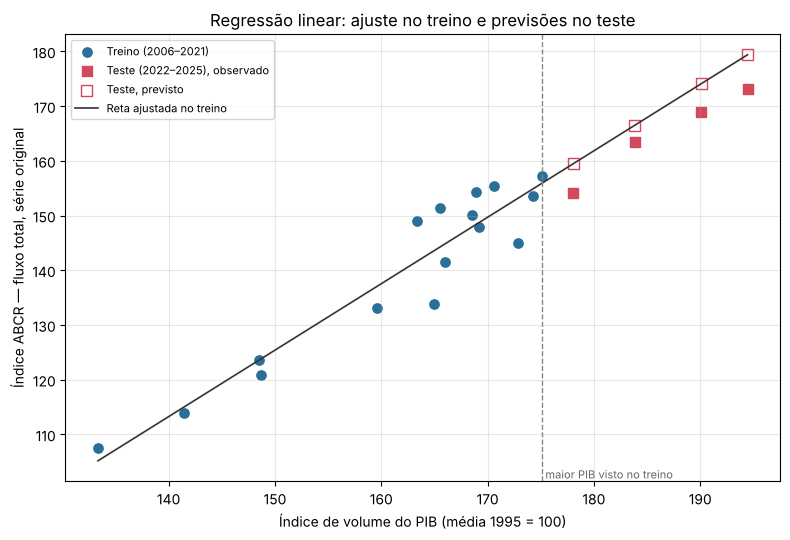

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(X_treino, y_treino, s=45, color="#2a6f97", label="Treino (2006–2021)")
ax.scatter(X_teste, y_teste, s=60, color="#d1495b", marker="s", label="Teste (2022–2025), observado")
ax.scatter(X_teste, y_prev, s=60, facecolors="none", edgecolors="#d1495b", marker="s", label="Teste, previsto")
xs = pd.DataFrame({"PIB_indice": np.linspace(base["PIB_indice"].min(), base["PIB_indice"].max(), 50)})
ax.plot(xs, modelo.predict(xs), color="#333", lw=1.2, label="Reta ajustada no treino")
ax.axvline(treino["PIB_indice"].max(), color="#888", ls="--", lw=1)
ax.text(treino["PIB_indice"].max(), ax.get_ylim()[0], " maior PIB visto no treino", fontsize=8, color="#666", va="bottom")
ax.set_xlabel("Índice de volume do PIB (média 1995 = 100)")
ax.set_ylabel("Índice ABCR — fluxo total, série original")
ax.set_title("Regressão linear: ajuste no treino e previsões no teste")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### O que cada métrica significa

- **MAE (erro absoluto médio):** média do tamanho dos erros, na mesma unidade do Índice ABCR. Um MAE de 3 quer dizer "em média, a estimativa erra 3 pontos de índice".
- **MSE (erro quadrático médio):** média dos erros ao quadrado. Como eleva ao quadrado, um erro grande pesa muito mais que vários pequenos — por isso é a métrica que denuncia previsões muito fora. A unidade fica "ao quadrado"; a raiz (RMSE) traz de volta para pontos de índice.
- **R² (coeficiente de determinação):** compara o modelo com o chute mais simples possível, que seria prever sempre a média dos valores de teste. 1 = previsão perfeita; 0 = empata com a média; **negativo = pior que a média**.

**Atenção ao R² deste teste:** ele é calculado com apenas 4 pontos, e a variação do índice entre esses 4 anos é pequena. Com denominador pequeno, erros modestos em pontos de índice já derrubam o R² (ele pode até ficar negativo) sem que as previsões estejam absurdamente longe. Por isso o MAE e o erro percentual da tabela dizem mais sobre "ficou perto ou não" do que o R² sozinho.

In [11]:
# Resumo numérico para apoiar a conclusão
pib_max_treino = treino["PIB_indice"].max()
fora = (teste["PIB_indice"] > pib_max_treino).sum()
vies = (y_prev - y_teste).mean()

print(f"Correlação PIB x ABCR (20 anos): r = {r_total:.3f}")
print(f"MAE = {mae:.2f} pontos de índice ({100 * mae / y_teste.mean():.1f}% do nível médio do teste)")
print(f"RMSE = {np.sqrt(mse):.2f} | R² no teste = {r2:.3f} | R² no treino = {modelo.score(X_treino, y_treino):.3f}")
print(f"Erro médio com sinal = {vies:+.2f} -> o modelo {'superestima' if vies > 0 else 'subestima'} o fluxo no teste")
print(f"{fora} de {len(teste)} anos de teste têm PIB acima do máximo do treino ({pib_max_treino:.2f}): extrapolação")

Correlação PIB x ABCR (20 anos): r = 0.964
MAE = 4.95 pontos de índice (3.0% do nível médio do teste)
RMSE = 5.09 | R² no teste = 0.485 | R² no treino = 0.901
Erro médio com sinal = +4.95 -> o modelo superestima o fluxo no teste
4 de 4 anos de teste têm PIB acima do máximo do treino (175.14): extrapolação


## 6. Conclusão

1. **Há relação positiva e forte** entre PIB e fluxo de veículos: a correlação de Pearson nos 20 anos é **r = 0,964**. Anos de maior atividade econômica são anos de mais veículos nas rodovias pedagiadas.
2. **A reta ajustada no treino** (2006–2021) foi `ABCR = 1,2145 × PIB − 56,78`, com R² de 0,901 no treino: cada ponto a mais no índice do PIB corresponde, em média, a 1,21 ponto no Índice ABCR.
3. **No teste (2022–2025) as estimativas ficaram próximas, mas com viés.** MAE = 4,95 pontos de índice (cerca de 3,0% do nível médio do período), MSE = 25,94 e R² = 0,485. O erro por ano ficou entre 1,8% e 3,6%. O R² bem menor que o do treino não significa previsões distantes: com só 4 pontos e pouca variação entre eles, um erro de 5 pontos já consome metade da variância.
4. **O modelo superestimou o fluxo nos quatro anos**, sempre no mesmo sentido (+3,0 a +6,3 pontos). Erro sistemático indica que a relação mudou de patamar, não que houve ruído: para um mesmo nível de PIB, o fluxo recente é menor que antes. Exemplo nos próprios dados: em 2013 o PIB foi 174,26 e o ABCR 153,59; em 2021, com PIB parecido (172,83), o ABCR foi 144,99. Uma hipótese é a mudança de hábitos de deslocamento depois da pandemia, mas os dados deste trabalho não permitem confirmar a causa.
5. **O teste é extrapolação.** Os quatro anos de teste têm PIB acima do máximo do treino (175,14, em 2014). A reta está sendo usada fora da faixa em que foi ajustada.
6. **O período de treino inclui quebras** que uma reta não captura: a recessão de 2015–2016 e, principalmente, 2020, quando o índice mensal caiu de 170,3 em janeiro para 82,4 em abril e a média anual do ABCR recuou 13,9% enquanto o PIB recuou 3,3%.
7. **Correlação não é causalidade.** Parte da correlação vem da tendência comum de crescimento das duas séries, e o Índice ABCR é ele próprio um dos insumos do PIB trimestral.

**Como melhorar:** mais observações (dados trimestrais em vez de anuais), separar veículos leves e pesados, modelar variações percentuais em vez de níveis para tirar a tendência comum, e validação cruzada temporal em vez de um único corte.

## 7. Dificuldades encontradas e soluções

| Dificuldade | Solução |
|---|---|
| A Tabela 1620 tem várias variáveis e setores; era fácil pegar a série com ajuste sazonal ou a taxa de variação por engano | Fixamos na consulta a variável 583 (índice de volume encadeado, sem ajuste) e o setor 90707 (PIB a preços de mercado), e conferimos a unidade "Número-índice" |
| Frequências diferentes: PIB trimestral e ABCR mensal | Reduzimos as duas para anual por média simples, conferindo antes se havia 4 trimestres e 12 meses em todos os anos |
| A planilha da ABCR reúne muitas séries (leves/pesados/total, regiões, original/dessazonalizada) com cabeçalho em mais de uma linha | Função de leitura que localiza a coluna de datas, reconstrói o cabeçalho e mostra qual coluna foi escolhida, para conferência visual |
| Risco de usar variação % no lugar do número-índice | Checagem automática da ordem de grandeza dos valores |
| `train_test_split` embaralha por padrão, o que vazaria o futuro para o treino | Corte manual por posição (`iloc`), mantendo a ordem cronológica |
| A coluna de datas da planilha vem com células vazias no cabeçalho, que o pandas lê como `NaT`; a primeira versão da leitura tratou `NaT` como data e perdeu o cabeçalho | Filtro com `pd.notna` ao identificar as células de data |
| R² instável com só 4 pontos de teste | Interpretação baseada em MAE e erro percentual junto com o R² |